# Weather Data Analysis using NumPy, Pandas and Matplotlib

**Objective:** Analyze daily weather data (2018-2023) to study trends and patterns.

**Dataset:** `../data/weather.csv` - date, temperature (°C), humidity (%), precipitation (mm).

## Setup: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Task 1: Load and Inspect Data

In [2]:
df = pd.read_csv("../data/weather.csv")
print("Shape:", df.shape)
df.head()

Shape: (2191, 4)


,date,temperature,humidity,precipitation
0,2018-01-01,20.7,60.0,0.0
1,2018-01-02,18.0,59.3,0.0
2,2018-01-03,21.5,65.2,0.5
3,2018-01-04,21.9,65.6,0.0
4,2018-01-05,16.1,53.1,0.0


In [3]:
df.info()
print()
print("Missing values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2191 entries, 0 to 2190
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           2191 non-null   str    
 1   temperature    2151 non-null   float64
 2   humidity       2151 non-null   float64
 3   precipitation  2151 non-null   float64
dtypes: float64(3), str(1)
memory usage: 68.6 KB

Missing values:
date              0
temperature      40
humidity         40
precipitation    40
dtype: int64


## Task 2: Data Cleaning
- Converted `date` to datetime.
- Filled missing temperature and humidity using interpolation (they change gradually).
- Filled missing precipitation with 0 (a missing reading most likely means no rain).

In [4]:
df["date"] = pd.to_datetime(df["date"])

df["temperature"] = df["temperature"].interpolate()
df["humidity"] = df["humidity"].interpolate()
df["precipitation"] = df["precipitation"].fillna(0)

print(df.isnull().sum())
print(df.dtypes)

date             0
temperature      0
humidity         0
precipitation    0
dtype: int64
date             datetime64[us]
temperature             float64
humidity                float64
precipitation           float64
dtype: object


## Task 3: Descriptive Statistics with NumPy

In [5]:
for col in ["temperature", "humidity", "precipitation"]:
    arr = df[col].to_numpy()
    print(col, "-> mean:", round(np.mean(arr), 2),
          "| median:", round(np.median(arr), 2),
          "| std:", round(np.std(arr), 2))

temperature -> mean: 25.89 | median: 25.8 | std: 4.66
humidity -> mean: 60.08 | median: 60.5 | std: 15.34
precipitation -> mean: 3.5 | median: 0.0 | std: 8.75


## Task 4: Monthly and Seasonal Analysis

In [6]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

def get_season(m):
    if m in (3, 4, 5):
        return "Summer"
    elif m in (6, 7, 8, 9):
        return "Monsoon"
    elif m in (10, 11):
        return "Post-monsoon"
    else:
        return "Winter"

df["season"] = df["month"].apply(get_season)
df.head()

,date,temperature,humidity,precipitation,year,month,season
0,2018-01-01,20.7,60.0,0.0,2018,1,Winter
1,2018-01-02,18.0,59.3,0.0,2018,1,Winter
2,2018-01-03,21.5,65.2,0.5,2018,1,Winter
3,2018-01-04,21.9,65.6,0.0,2018,1,Winter
4,2018-01-05,16.1,53.1,0.0,2018,1,Winter


In [7]:
monthly = df.groupby("month")[["temperature", "humidity", "precipitation"]].mean().round(2)
print("Monthly averages")
display(monthly)

seasonal = df.groupby("season")[["temperature", "humidity", "precipitation"]].mean().round(2)
print("Seasonal averages")
display(seasonal)

Monthly averages


,temperature,humidity,precipitation
month,,,
1,20.18,60.94,0.59
2,21.14,50.30,0.43
3,23.18,43.40,0.27
4,26.26,40.29,0.52
5,29.22,42.70,0.50
6,31.39,49.49,10.71
7,31.86,59.45,9.70
8,30.54,69.35,9.00
9,28.27,75.85,9.09


Seasonal averages


,temperature,humidity,precipitation
season,,,
Monsoon,30.53,63.55,9.62
Post-monsoon,24.01,79.07,0.44
Summer,26.22,42.15,0.43
Winter,20.57,60.85,0.44


## Task 5: Visualizations

### Line plot: average monthly temperature

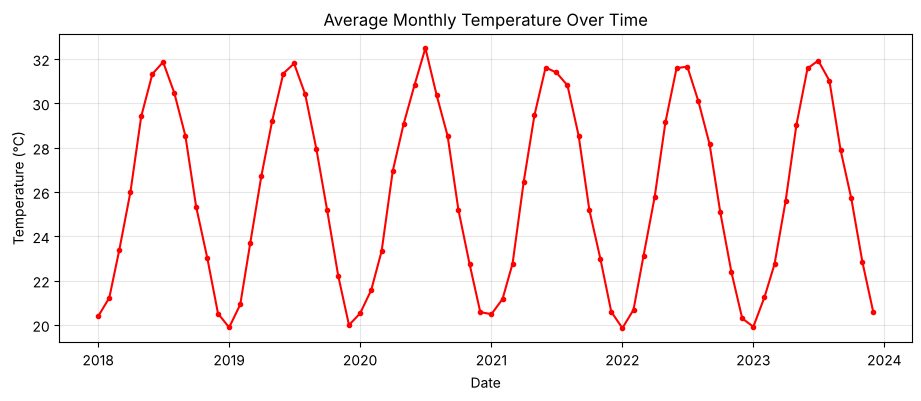

In [8]:
monthly_temp = df.set_index("date")["temperature"].resample("MS").mean()

plt.figure(figsize=(11, 4))
plt.plot(monthly_temp.index, monthly_temp.values, color="red", marker="o", markersize=3)
plt.title("Average Monthly Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.show()

### Line plot: average temperature by year

year
2018    25.99
2019    25.81
2020    26.03
2021    25.98
2022    25.68
2023    25.87
Name: temperature, dtype: float64


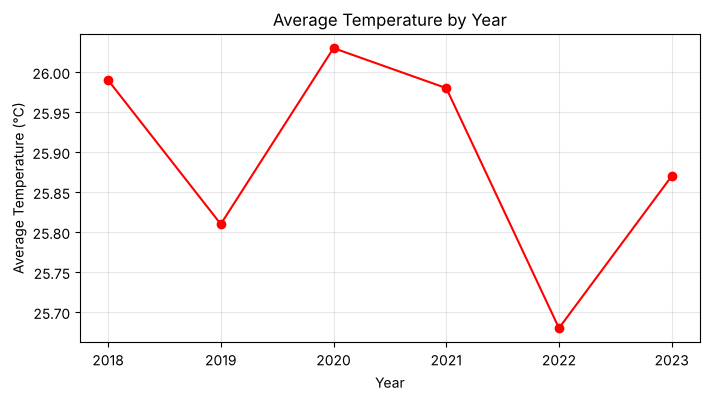

In [9]:
yearly_avg = df.groupby("year")["temperature"].mean().round(2)
print(yearly_avg)

plt.figure(figsize=(8, 4))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o", color="red")
plt.title("Average Temperature by Year")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(alpha=0.3)
plt.show()

### Bar plot: average precipitation by month

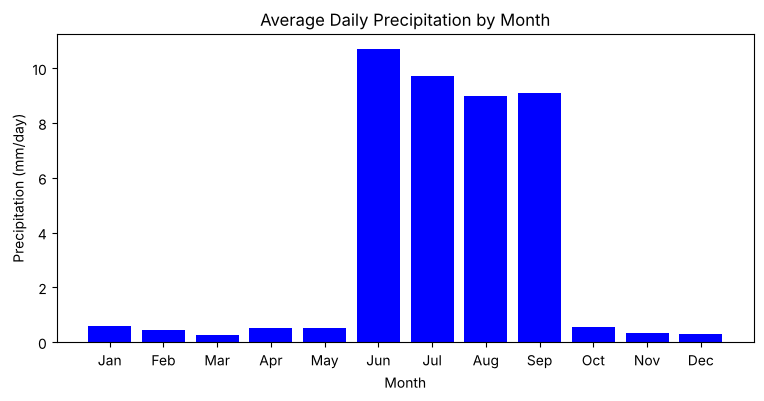

In [10]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(9, 4))
plt.bar(month_names, monthly["precipitation"], color="blue")
plt.title("Average Daily Precipitation by Month")
plt.xlabel("Month")
plt.ylabel("Precipitation (mm/day)")
plt.show()

### Histogram: temperature distribution

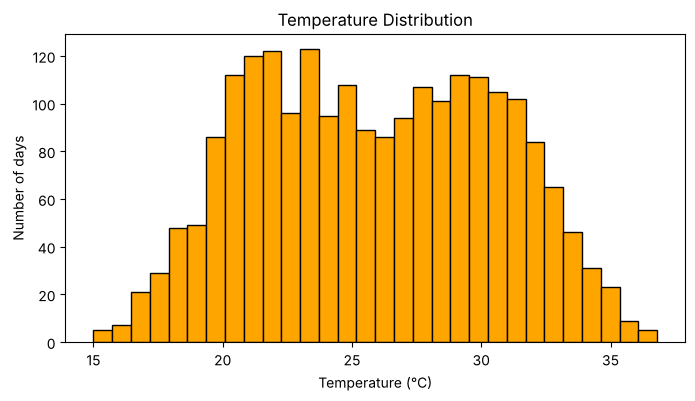

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(df["temperature"], bins=30, color="orange", edgecolor="black")
plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of days")
plt.show()

## Task 6: Identify Extreme Weather

In [12]:
temp = df["temperature"].to_numpy()
rain = df["precipitation"].to_numpy()

hot_limit = np.percentile(temp, 95)
cold_limit = np.percentile(temp, 5)
rain_limit = np.percentile(rain[rain > 0], 95)

print("Hot limit:", round(hot_limit, 1), "°C")
print("Cold limit:", round(cold_limit, 1), "°C")
print("Heavy rain limit:", round(rain_limit, 1), "mm")

hot_days = df[temp >= hot_limit]
cold_days = df[temp <= cold_limit]
heavy_rain_days = df[rain >= rain_limit]

print("Hot days:", len(hot_days))
print("Cold days:", len(cold_days))
print("Heavy rain days:", len(heavy_rain_days))

heavy_rain_days.sort_values("precipitation", ascending=False).head(10)

Hot limit: 33.2 °C
Cold limit: 18.6 °C
Heavy rain limit: 37.4 mm
Hot days: 114
Cold days: 110
Heavy rain days: 37


,date,temperature,humidity,precipitation,year,month,season
562,2019-07-17,32.1,60.0,78.6,2019,7,Monsoon
261,2018-09-19,27.5,80.8,78.4,2018,9,Monsoon
269,2018-09-27,27.3,71.1,67.1,2018,9,Monsoon
213,2018-08-02,30.6,59.6,64.0,2018,8,Monsoon
1307,2021-07-31,34.1,62.7,62.2,2021,7,Monsoon
1992,2023-06-16,31.9,63.4,59.5,2023,6,Monsoon
1256,2021-06-10,32.8,53.4,58.5,2021,6,Monsoon
913,2020-07-02,30.7,54.1,55.8,2020,7,Monsoon
1614,2022-06-03,29.5,30.0,54.6,2022,6,Monsoon
904,2020-06-23,30.5,44.9,54.0,2020,6,Monsoon


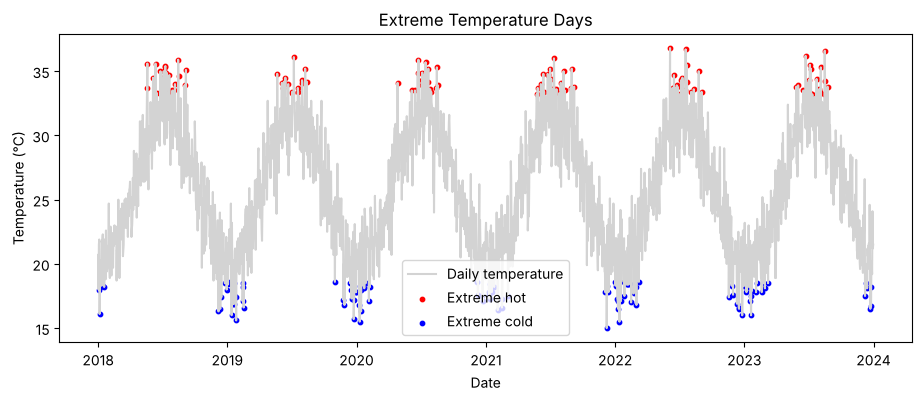

In [13]:
plt.figure(figsize=(11, 4))
plt.plot(df["date"], df["temperature"], color="lightgray", label="Daily temperature")
plt.scatter(hot_days["date"], hot_days["temperature"], color="red", s=10, label="Extreme hot")
plt.scatter(cold_days["date"], cold_days["temperature"], color="blue", s=10, label="Extreme cold")
plt.title("Extreme Temperature Days")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()

## Conclusion
- Temperature peaks in June-July and is lowest in December-January.
- Most rain falls in the monsoon (June-September).
- Humidity is highest after the monsoon, in October-November.
- Yearly average temperature is flat (25.7-26.0 °C), so there is no clear long-term trend.
- Extreme hot days fall in summer/monsoon months and extreme cold days in winter.